In [1]:
import pandas as pd

rgb = pd.read_csv("rgb2-features.csv")
weights = pd.read_csv("plant-weights.csv")

In [3]:
print(rgb.columns.tolist())
print(weights.columns.tolist())

['sample_key', 'experiment_id', 'plant_id', 'round_id', 'modality', 'date', 'time', 'datetime', 'timestamp', 'image_timestamp', 'image_date', 'image_time', 'qc_flags', 'image_height_px', 'image_width_px', 'image_channels', 'tray_roi_crop_row_start_px', 'tray_roi_crop_row_stop_px', 'tray_roi_crop_col_start_px', 'tray_roi_crop_col_stop_px', 'tray_roi_crop_row_start_norm', 'tray_roi_crop_row_stop_norm', 'tray_roi_crop_col_start_norm', 'tray_roi_crop_col_stop_norm', 'feature_bbox_row_start_px', 'feature_bbox_row_stop_px', 'feature_bbox_col_start_px', 'feature_bbox_col_stop_px', 'thumbnail_variable_id', 'thumbnail_variable_name', 'thumbnail_source_kind', 'thumbnail_scale_method', 'thumbnail_vmin', 'thumbnail_vmax', 's3d_coordinate_unit', 's3d_point_cloud_format', 's3d_point_cloud_fields', 's3d_plant_surface_format', 'thumbnail_path', 'vit_mask_path', 'appl_mask_path', 'point_cloud_path', 'plant_surface_path', 's3d_viewer_path', 'area_px', 'perimeter_px', 'bbox_height_px', 'bbox_width_px', '

In [5]:
rgb[['plant_id','round_id']].duplicated().sum()
weights[['plant_id','round_id']].duplicated().sum()

12

In [7]:
rgb_duplicates = rgb[
    rgb.duplicated(
        subset=['plant_id', 'round_id'],
        keep=False
    )
].sort_values(['plant_id', 'round_id'])

print(rgb_duplicates[
    ['plant_id', 'round_id']
].drop_duplicates())


Empty DataFrame
Columns: [plant_id, round_id]
Index: []


In [9]:
weight_duplicates = weights[
    weights.duplicated(
        subset=['plant_id', 'round_id'],
        keep=False
    )
].sort_values(['plant_id', 'round_id'])

print(weight_duplicates[
    ['plant_id', 'round_id']
].drop_duplicates())

       plant_id  round_id
21198     28893      5707
21200     28894      5707
21202     28895      5707
21204     28896      5707
21206     28897      5707
21208     28898      5707
21564     28899      5709
21566     28900      5709
21568     28901      5709
21570     28902      5709
21572     28903      5709
21574     28904      5709


In [11]:
rgb[['plant_id','round_id','timestamp']].duplicated().sum()

weights[['plant_id','round_id','timestamp']].duplicated().sum()

12

In [13]:
rgb_duplicates.head(20)

,sample_key,experiment_id,plant_id,round_id,modality,date,time,datetime,timestamp,image_timestamp,...,hue_bin_15_216p0_230p4deg_prop,hue_bin_16_230p4_244p8deg_prop,hue_bin_17_244p8_259p2deg_prop,hue_bin_18_259p2_273p6deg_prop,hue_bin_19_273p6_288p0deg_prop,hue_bin_20_288p0_302p4deg_prop,hue_bin_21_302p4_316p8deg_prop,hue_bin_22_316p8_331p2deg_prop,hue_bin_23_331p2_345p6deg_prop,hue_bin_24_345p6_360p0deg_prop


In [15]:
print(rgb[['plant_id','round_id']].duplicated().sum())

print(weights[['plant_id','round_id']].duplicated().sum())

print(rgb.shape)

print(weights.shape)


0
12
(23580, 111)
(25752, 26)


In [17]:
duplicate_rows = weights[
    weights.duplicated(
        subset=['plant_id', 'round_id'],
        keep=False
    )
]

print(
    duplicate_rows[
        ['plant_id', 'round_id']
    ].sort_values(
        ['plant_id', 'round_id']
    )
)

       plant_id  round_id
21198     28893      5707
21199     28893      5707
21200     28894      5707
21201     28894      5707
21202     28895      5707
21203     28895      5707
21204     28896      5707
21205     28896      5707
21206     28897      5707
21207     28897      5707
21208     28898      5707
21209     28898      5707
21564     28899      5709
21565     28899      5709
21566     28900      5709
21567     28900      5709
21568     28901      5709
21569     28901      5709
21570     28902      5709
21571     28902      5709
21572     28903      5709
21573     28903      5709
21574     28904      5709
21575     28904      5709


In [19]:
duplicate_rows.head(20)

,sample_key,experiment_id,plant_id,round_id,modality,date,time,datetime,timestamp,scale_measure_id,...,tray_id,tray_profile_id,tray_barcode,tray_info,tray_area,plant_barcode,plant_name,plant_info,weight_g,weight_after_watering_g
21198,67__28893__5707__plant_weights__sc1__measure-4...,67,28893,5707,plant_weights,2026-05-02,23:59:04,2026-05-02 23:59:04,2026-05-02 23:59:04,452670,...,1567,10249,XX APPL 21,Row 25,A1,2026.04.09_OPAL.0002_Weston_PC_1.0_121,PC,121_PC.6_1000_rep1,155.3,181.4
21199,67__28893__5707__plant_weights__sc1__measure-4...,67,28893,5707,plant_weights,2026-05-02,23:59:04,2026-05-02 23:59:04,2026-05-02 23:59:04,452670,...,1567,10249,XX APPL 21,Row 25,A1,2026.04.09_OPAL.0002_Weston_PC_1.0_121,PC,121_PC.6_1000_rep1,181.2,181.2
21200,67__28894__5707__plant_weights__sc1__measure-4...,67,28894,5707,plant_weights,2026-05-02,23:59:04,2026-05-02 23:59:04,2026-05-02 23:59:04,452670,...,1567,10249,XX APPL 21,Row 25,A3,2026.04.09_OPAL.0002_Weston_PC_1.0_122,PC,122_PC.1_500_rep2,119.6,163.7
21201,67__28894__5707__plant_weights__sc1__measure-4...,67,28894,5707,plant_weights,2026-05-02,23:59:04,2026-05-02 23:59:04,2026-05-02 23:59:04,452670,...,1567,10249,XX APPL 21,Row 25,A3,2026.04.09_OPAL.0002_Weston_PC_1.0_122,PC,122_PC.1_500_rep2,162.2,196.3
21202,67__28895__5707__plant_weights__sc1__measure-4...,67,28895,5707,plant_weights,2026-05-02,23:59:04,2026-05-02 23:59:04,2026-05-02 23:59:04,452670,...,1567,10249,XX APPL 21,Row 25,A5,2026.04.09_OPAL.0002_Weston_PC_1.0_123,PC,123_PC.3_100_rep4,153.6,188.9
21203,67__28895__5707__plant_weights__sc1__measure-4...,67,28895,5707,plant_weights,2026-05-02,23:59:04,2026-05-02 23:59:04,2026-05-02 23:59:04,452670,...,1567,10249,XX APPL 21,Row 25,A5,2026.04.09_OPAL.0002_Weston_PC_1.0_123,PC,123_PC.3_100_rep4,184.8,188.8
21204,67__28896__5707__plant_weights__sc1__measure-4...,67,28896,5707,plant_weights,2026-05-02,23:59:04,2026-05-02 23:59:04,2026-05-02 23:59:04,452670,...,1567,10249,XX APPL 21,Row 25,C1,2026.04.09_OPAL.0002_Weston_PC_1.0_124,PC,124_PC.1_1000_rep4,172.1,183.8
21205,67__28896__5707__plant_weights__sc1__measure-4...,67,28896,5707,plant_weights,2026-05-02,23:59:04,2026-05-02 23:59:04,2026-05-02 23:59:04,452670,...,1567,10249,XX APPL 21,Row 25,C1,2026.04.09_OPAL.0002_Weston_PC_1.0_124,PC,124_PC.1_1000_rep4,183.7,183.7
21206,67__28897__5707__plant_weights__sc1__measure-4...,67,28897,5707,plant_weights,2026-05-02,23:59:04,2026-05-02 23:59:04,2026-05-02 23:59:04,452670,...,1567,10249,XX APPL 21,Row 25,C3,2026.04.09_OPAL.0002_Weston_PC_1.0_125,PC,125_PC.12_0_rep4,167.4,183.0
21207,67__28897__5707__plant_weights__sc1__measure-4...,67,28897,5707,plant_weights,2026-05-02,23:59:04,2026-05-02 23:59:04,2026-05-02 23:59:04,452670,...,1567,10249,XX APPL 21,Row 25,C3,2026.04.09_OPAL.0002_Weston_PC_1.0_125,PC,125_PC.12_0_rep4,182.6,182.6


In [21]:
weights[
    weights.duplicated(
        subset=['plant_id','round_id','timestamp'],
        keep=False
    )
].shape

(24, 26)

In [23]:
weights[
    weights.duplicated(
        subset=['plant_id','round_id','datetime'],
        keep=False
    )
].shape

(24, 26)

In [25]:
duplicates = weights[
    weights.duplicated(
        subset=['plant_id', 'round_id'],
        keep=False
    )
]

duplicates = duplicates.sort_values(
    ['plant_id', 'round_id']
)

print(
    duplicates[
        ['plant_id',
         'round_id',
         'timestamp',
         'weight_g']
    ]
)

       plant_id  round_id            timestamp  weight_g
21198     28893      5707  2026-05-02 23:59:04     155.3
21199     28893      5707  2026-05-02 23:59:04     181.2
21200     28894      5707  2026-05-02 23:59:04     119.6
21201     28894      5707  2026-05-02 23:59:04     162.2
21202     28895      5707  2026-05-02 23:59:04     153.6
21203     28895      5707  2026-05-02 23:59:04     184.8
21204     28896      5707  2026-05-02 23:59:04     172.1
21205     28896      5707  2026-05-02 23:59:04     183.7
21206     28897      5707  2026-05-02 23:59:04     167.4
21207     28897      5707  2026-05-02 23:59:04     182.6
21208     28898      5707  2026-05-02 23:59:04     130.9
21209     28898      5707  2026-05-02 23:59:04     179.7
21564     28899      5709  2026-05-03 08:29:58     175.6
21565     28899      5709  2026-05-03 08:29:58     181.5
21566     28900      5709  2026-05-03 08:29:58     167.6
21567     28900      5709  2026-05-03 08:29:58     179.2
21568     28901      5709  2026

In [27]:
weights[['plant_id','round_id','timestamp']].duplicated().sum()

12

In [29]:
weights = weights.drop_duplicates()


In [31]:
weights[['plant_id','round_id','timestamp']].duplicated().sum()

12

In [33]:
weights.duplicated().sum()

0

In [35]:
duplicates.groupby(
    ['plant_id','round_id','timestamp']
).head(2)

,sample_key,experiment_id,plant_id,round_id,modality,date,time,datetime,timestamp,scale_measure_id,...,tray_id,tray_profile_id,tray_barcode,tray_info,tray_area,plant_barcode,plant_name,plant_info,weight_g,weight_after_watering_g
21198,67__28893__5707__plant_weights__sc1__measure-4...,67,28893,5707,plant_weights,2026-05-02,23:59:04,2026-05-02 23:59:04,2026-05-02 23:59:04,452670,...,1567,10249,XX APPL 21,Row 25,A1,2026.04.09_OPAL.0002_Weston_PC_1.0_121,PC,121_PC.6_1000_rep1,155.3,181.4
21199,67__28893__5707__plant_weights__sc1__measure-4...,67,28893,5707,plant_weights,2026-05-02,23:59:04,2026-05-02 23:59:04,2026-05-02 23:59:04,452670,...,1567,10249,XX APPL 21,Row 25,A1,2026.04.09_OPAL.0002_Weston_PC_1.0_121,PC,121_PC.6_1000_rep1,181.2,181.2
21200,67__28894__5707__plant_weights__sc1__measure-4...,67,28894,5707,plant_weights,2026-05-02,23:59:04,2026-05-02 23:59:04,2026-05-02 23:59:04,452670,...,1567,10249,XX APPL 21,Row 25,A3,2026.04.09_OPAL.0002_Weston_PC_1.0_122,PC,122_PC.1_500_rep2,119.6,163.7
21201,67__28894__5707__plant_weights__sc1__measure-4...,67,28894,5707,plant_weights,2026-05-02,23:59:04,2026-05-02 23:59:04,2026-05-02 23:59:04,452670,...,1567,10249,XX APPL 21,Row 25,A3,2026.04.09_OPAL.0002_Weston_PC_1.0_122,PC,122_PC.1_500_rep2,162.2,196.3
21202,67__28895__5707__plant_weights__sc1__measure-4...,67,28895,5707,plant_weights,2026-05-02,23:59:04,2026-05-02 23:59:04,2026-05-02 23:59:04,452670,...,1567,10249,XX APPL 21,Row 25,A5,2026.04.09_OPAL.0002_Weston_PC_1.0_123,PC,123_PC.3_100_rep4,153.6,188.9
21203,67__28895__5707__plant_weights__sc1__measure-4...,67,28895,5707,plant_weights,2026-05-02,23:59:04,2026-05-02 23:59:04,2026-05-02 23:59:04,452670,...,1567,10249,XX APPL 21,Row 25,A5,2026.04.09_OPAL.0002_Weston_PC_1.0_123,PC,123_PC.3_100_rep4,184.8,188.8
21204,67__28896__5707__plant_weights__sc1__measure-4...,67,28896,5707,plant_weights,2026-05-02,23:59:04,2026-05-02 23:59:04,2026-05-02 23:59:04,452670,...,1567,10249,XX APPL 21,Row 25,C1,2026.04.09_OPAL.0002_Weston_PC_1.0_124,PC,124_PC.1_1000_rep4,172.1,183.8
21205,67__28896__5707__plant_weights__sc1__measure-4...,67,28896,5707,plant_weights,2026-05-02,23:59:04,2026-05-02 23:59:04,2026-05-02 23:59:04,452670,...,1567,10249,XX APPL 21,Row 25,C1,2026.04.09_OPAL.0002_Weston_PC_1.0_124,PC,124_PC.1_1000_rep4,183.7,183.7
21206,67__28897__5707__plant_weights__sc1__measure-4...,67,28897,5707,plant_weights,2026-05-02,23:59:04,2026-05-02 23:59:04,2026-05-02 23:59:04,452670,...,1567,10249,XX APPL 21,Row 25,C3,2026.04.09_OPAL.0002_Weston_PC_1.0_125,PC,125_PC.12_0_rep4,167.4,183.0
21207,67__28897__5707__plant_weights__sc1__measure-4...,67,28897,5707,plant_weights,2026-05-02,23:59:04,2026-05-02 23:59:04,2026-05-02 23:59:04,452670,...,1567,10249,XX APPL 21,Row 25,C3,2026.04.09_OPAL.0002_Weston_PC_1.0_125,PC,125_PC.12_0_rep4,182.6,182.6


In [37]:
duplicates[
    ['plant_id',
     'round_id',
     'weight_g',
     'weight_after_watering_g']
].head(10)

,plant_id,round_id,weight_g,weight_after_watering_g
21198,28893,5707,155.3,181.4
21199,28893,5707,181.2,181.2
21200,28894,5707,119.6,163.7
21201,28894,5707,162.2,196.3
21202,28895,5707,153.6,188.9
21203,28895,5707,184.8,188.8
21204,28896,5707,172.1,183.8
21205,28896,5707,183.7,183.7
21206,28897,5707,167.4,183.0
21207,28897,5707,182.6,182.6


In [39]:
weights_clean = weights[
    weights['weight_after_watering_g'].notna()
].copy()

In [41]:
weights_clean[
    ['plant_id', 'round_id']
].duplicated().sum()

12

In [43]:
weights_clean = (
    weights
    .sort_values(['plant_id','round_id'])
    .drop_duplicates(
        subset=['plant_id','round_id'],
        keep='last'
    )
)


In [45]:
weights_clean[
    ['plant_id','round_id']
].duplicated().sum()

0

In [47]:
merged = pd.merge(
    rgb,
    weights_clean[['plant_id', 'round_id', 'weight_g']],
    on=['plant_id', 'round_id'],
    how='inner'
)

print(merged.shape)

(23580, 112)


In [49]:
print(merged['weight_g'].isna().sum())

0


In [51]:
numeric_cols = merged.select_dtypes(include='number')

corrs = (
    numeric_cols
    .corr()['weight_g']
    .sort_values(ascending=False)
)

print(corrs.head(20))

weight_g                          1.000000
red_median                        0.315209
lightness_median                  0.305878
red_mean                          0.303202
brightness_median                 0.300684
lightness_mean                    0.289038
green_median                      0.288921
brightness_mean                   0.285220
green_mean                        0.273241
hue_bin_04_057p6_072p0deg_prop    0.232701
blue_mean                         0.215736
blue-yellow_median                0.201061
blue_median                       0.196823
hue_bin_03_043p2_057p6deg_prop    0.193107
proportional_red_mean             0.171484
feature_bbox_row_start_px         0.157511
bbox_top_px                       0.157511
hue_bin_10_144p0_158p4deg_prop    0.157226
hue_bin_13_187p2_201p6deg_prop    0.152339
hue_bin_12_172p8_187p2deg_prop    0.149419
Name: weight_g, dtype: float64


In [53]:
size_features = [
    'area_mm2',
    'convex_area_mm2',
    'perimeter_mm',
    'bbox_height_px',
    'bbox_width_px',
    'area_px',
    'convex_area_px',
    'perimeter_px'
]

for feature in size_features:
    if feature in corrs.index:
        print(feature, corrs[feature])

area_mm2 -0.5237628033547104
convex_area_mm2 -0.5133384633608382
perimeter_mm -0.4515491442383547
bbox_height_px -0.48349209786697883
bbox_width_px -0.4821126387833832
area_px -0.523762803354712
convex_area_px -0.5133384633608372
perimeter_px -0.4515518899040266


In [55]:
features = [
    'area_mm2',
    'convex_area_mm2',
    'perimeter_mm',
    'bbox_height_px',
    'bbox_width_px'
]

X = merged[features]
y = merged['weight_g']

In [57]:
print(X.isna().sum())

area_mm2           4690
convex_area_mm2    4690
perimeter_mm       4690
bbox_height_px     4690
bbox_width_px      4690
dtype: int64


In [59]:
model_data = merged.dropna(
    subset=[
        'area_mm2',
        'convex_area_mm2',
        'perimeter_mm',
        'bbox_height_px',
        'bbox_width_px'
    ]
)

print(model_data.shape)

(18890, 112)


In [61]:
print(
    model_data[
        [
            'area_mm2',
            'convex_area_mm2',
            'perimeter_mm',
            'bbox_height_px',
            'bbox_width_px'
        ]
    ].isna().sum()
)

area_mm2           0
convex_area_mm2    0
perimeter_mm       0
bbox_height_px     0
bbox_width_px      0
dtype: int64


In [63]:
features = [
    'area_mm2',
    'convex_area_mm2',
    'perimeter_mm',
    'bbox_height_px',
    'bbox_width_px'
]

X = model_data[features]
y = model_data['weight_g']

In [65]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

In [67]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

LinearRegression()

In [69]:
predictions = model.predict(X_test)

In [71]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

print("R² =", r2_score(y_test, predictions))
print("MAE =", mean_absolute_error(y_test, predictions))
print("RMSE =", mean_squared_error(y_test, predictions) ** 0.5)

R² = 0.20846507854577934
MAE = 13.644613593258388
RMSE = 22.51035436524484


In [73]:
features = [
    'area_mm2',
    'convex_area_mm2',
    'perimeter_mm',
    'bbox_height_px',
    'bbox_width_px',
    'red_mean',
    'green_mean',
    'red_median',
    'lightness_mean',
    'brightness_mean'
]

In [75]:
print(model_data[features].isna().sum())

area_mm2           0
convex_area_mm2    0
perimeter_mm       0
bbox_height_px     0
bbox_width_px      0
red_mean           0
green_mean         0
red_median         0
lightness_mean     0
brightness_mean    0
dtype: int64


In [77]:
features = [
    'area_mm2',
    'convex_area_mm2',
    'perimeter_mm',
    'bbox_height_px',
    'bbox_width_px',
    'red_mean',
    'green_mean',
    'red_median',
    'lightness_mean',
    'brightness_mean'
]

X = model_data[features]
y = model_data['weight_g']

In [79]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

In [81]:
from sklearn.linear_model import LinearRegression

model2 = LinearRegression()
model2.fit(X_train, y_train)

predictions2 = model2.predict(X_test)

In [83]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

print("R² =", r2_score(y_test, predictions2))
print("MAE =", mean_absolute_error(y_test, predictions2))
print("RMSE =", mean_squared_error(y_test, predictions2) ** 0.5)

R² = 0.2176131157765382
MAE = 13.507590126112339
RMSE = 22.379896437645442


In [85]:
# Polynomial Regression:

In [87]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

poly_model = Pipeline([
    ('poly', PolynomialFeatures(degree=2)),
    ('linear', LinearRegression())
])

poly_model.fit(X_train, y_train)

poly_pred = poly_model.predict(X_test)

print("R² =", r2_score(y_test, poly_pred))
print("MAE =", mean_absolute_error(y_test, poly_pred))
print("RMSE =", mean_squared_error(y_test, poly_pred) ** 0.5)

R² = 0.2505634407898176
MAE = 13.113619240183
RMSE = 21.90356114133688


In [89]:
# Checking for overfitting:
train_pred = poly_model.predict(X_train)

from sklearn.metrics import r2_score

print("Training R² =", r2_score(y_train, train_pred))
print("Testing R² =", r2_score(y_test, poly_pred))

Training R² = 0.3720776766455104
Testing R² = 0.2505634407898176


In [91]:
corrs = (
    model_data
    .select_dtypes(include='number')
    .corr()['weight_g']
    .abs()
    .sort_values(ascending=False)
)

print(corrs.head(30))

weight_g                          1.000000
mask_coverage_pct                 0.529710
area_px                           0.523763
area_mm2                          0.523763
convex_area_mm2                   0.513338
convex_area_px                    0.513338
bbox_height_mm                    0.483492
bbox_height_px                    0.483492
bbox_width_px                     0.482113
bbox_width_mm                     0.482113
convex_perimeter_px               0.472241
convex_perimeter_mm               0.472231
perimeter_px                      0.451552
perimeter_mm                      0.451549
round_id                          0.425634
hue_bin_06_086p4_100p8deg_prop    0.338173
red_median                        0.315209
lightness_median                  0.305878
red_mean                          0.303202
brightness_median                 0.300684
lightness_mean                    0.289038
green_median                      0.288921
brightness_mean                   0.285220
green_mean 

In [93]:
# Using mask coverage:
features = [
    'mask_coverage_pct',
    'area_mm2',
    'convex_area_mm2',
    'bbox_height_px',
    'bbox_width_px',
    'convex_perimeter_px',
    'perimeter_px',
    'red_mean',
    'green_mean',
    'lightness_mean',
    'brightness_mean',
    'ngrdi_mean'
]

In [95]:
print(model_data[features].isna().sum())

mask_coverage_pct      0
area_mm2               0
convex_area_mm2        0
bbox_height_px         0
bbox_width_px          0
convex_perimeter_px    0
perimeter_px           0
red_mean               0
green_mean             0
lightness_mean         0
brightness_mean        0
ngrdi_mean             0
dtype: int64


In [117]:
features = [
    'mask_coverage_pct',
    'area_mm2',
    'convex_area_mm2',
    'red_mean',
    'green_mean',
    'lightness_mean',
    'brightness_mean',
    'ngrdi_mean'
]

X = model_data[features]
y = model_data['weight_g']

In [119]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)


In [121]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

poly_model2 = Pipeline([
    ('poly', PolynomialFeatures(degree=2)),
    ('linear', LinearRegression())
])

poly_model2.fit(X_train, y_train)

Pipeline(steps=[('poly', PolynomialFeatures()), ('linear', LinearRegression())])

In [123]:
predictions = poly_model2.predict(X_test)

In [125]:
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

print("R² =", r2_score(y_test, predictions))
print("MAE =", mean_absolute_error(y_test, predictions))
print("RMSE =", mean_squared_error(y_test, predictions) ** 0.5)

R² = 0.25083714927337597
MAE = 13.079527336365402
RMSE = 21.899560977533678


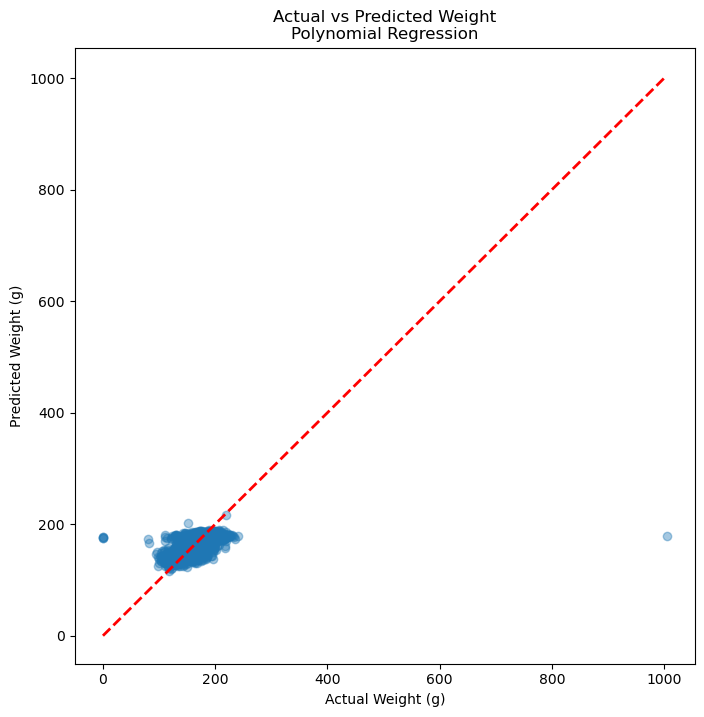

In [127]:
# Using best model so far (still not good)

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 8))

plt.scatter(
    y_test,
    predictions,
    alpha=0.4
)

min_val = min(y_test.min(), predictions.min())
max_val = max(y_test.max(), predictions.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    'r--',
    linewidth=2
)

plt.xlabel("Actual Weight (g)")
plt.ylabel("Predicted Weight (g)")
plt.title("Actual vs Predicted Weight\nPolynomial Regression")

plt.show()


/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:493: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


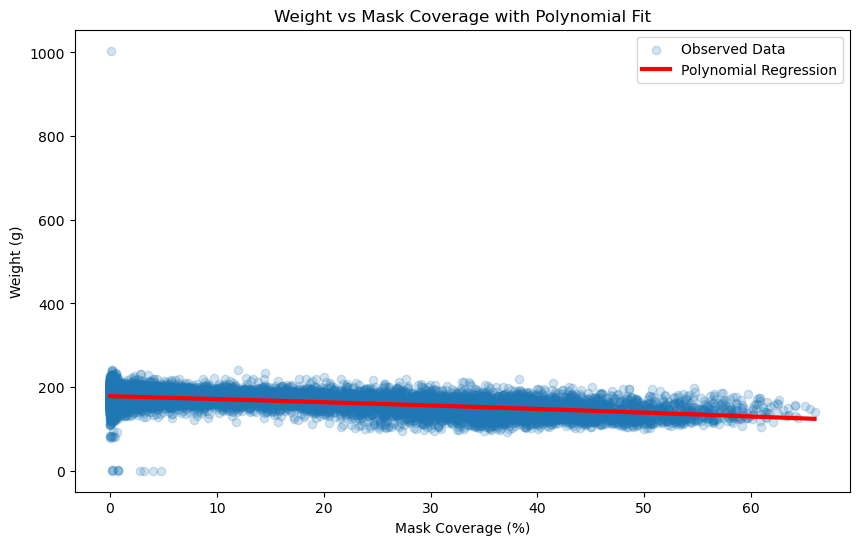

In [129]:
# Using only the top 2 predictors:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

x = model_data[['mask_coverage_pct']]
y = model_data['weight_g']

poly = PolynomialFeatures(degree=2)
x_poly = poly.fit_transform(x)

model = LinearRegression()
model.fit(x_poly, y)

x_sorted = np.sort(x.values.flatten())
x_sorted_poly = poly.transform(x_sorted.reshape(-1, 1))

y_curve = model.predict(x_sorted_poly)

plt.figure(figsize=(10,6))

plt.scatter(
    x,
    y,
    alpha=0.2,
    label='Observed Data'
)

plt.plot(
    x_sorted,
    y_curve,
    color='red',
    linewidth=3,
    label='Polynomial Regression'
)

plt.xlabel('Mask Coverage (%)')
plt.ylabel('Weight (g)')
plt.title('Weight vs Mask Coverage with Polynomial Fit')
plt.legend()

plt.show()

In [132]:
corrs = (
    model_data
    .select_dtypes(include='number')
    .corr()['convex_area_mm2']
    .abs()
    .sort_values(ascending=False)
)

print(corrs.head(30))

convex_area_mm2                   1.000000
convex_area_px                    1.000000
area_px                           0.989880
area_mm2                          0.989880
mask_coverage_pct                 0.985152
bbox_height_mm                    0.954879
bbox_height_px                    0.954879
perimeter_mm                      0.948274
perimeter_px                      0.948273
bbox_width_px                     0.947412
bbox_width_mm                     0.947412
convex_perimeter_px               0.936271
convex_perimeter_mm               0.936253
round_id                          0.701055
hue_bin_06_086p4_100p8deg_prop    0.561218
weight_g                          0.513338
red_median                        0.458405
red_mean                          0.437909
lightness_median                  0.423438
proportional_green_mean           0.422549
brightness_median                 0.422425
green_median                      0.387691
ngrdi_mean                        0.385501
brightness_

In [134]:
features = [
    'mask_coverage_pct',
    'bbox_height_px',
    'bbox_width_px',
    'perimeter_px',
    'convex_perimeter_px',
    'red_mean',
    'green_mean',
    'brightness_mean',
    'ngrdi_mean',
    'round_id'
]

X = model_data[features]
y = model_data['convex_area_mm2']

In [136]:
print(X.isna().sum())


mask_coverage_pct      0
bbox_height_px         0
bbox_width_px          0
perimeter_px           0
convex_perimeter_px    0
red_mean               0
green_mean             0
brightness_mean        0
ngrdi_mean             0
round_id               0
dtype: int64


In [138]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

In [140]:
from sklearn.linear_model import LinearRegression

convex_model = LinearRegression()

convex_model.fit(X_train, y_train)

convex_pred = convex_model.predict(X_test)

In [142]:
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

print("R² =", r2_score(y_test, convex_pred))
print("MAE =", mean_absolute_error(y_test, convex_pred))
print("RMSE =", mean_squared_error(y_test, convex_pred)**0.5)

R² = 0.9855206337051726
MAE = 2.6578391596416266
RMSE = 4.161228652516764


In [144]:
target = 'convex_area_mm2'

corrs = (
    model_data
    .select_dtypes(include='number')
    .corr()[target]
    .abs()
    .sort_values(ascending=False)
)

print(corrs[corrs > 0.95])

convex_area_mm2      1.000000
convex_area_px       1.000000
area_px              0.989880
area_mm2             0.989880
mask_coverage_pct    0.985152
bbox_height_mm       0.954879
bbox_height_px       0.954879
Name: convex_area_mm2, dtype: float64


In [146]:
train_pred = convex_model.predict(X_train)

from sklearn.metrics import r2_score

print("Training R²:", r2_score(y_train, train_pred))
print("Testing R²:", r2_score(y_test, convex_pred))

Training R²: 0.9856218160279646
Testing R²: 0.9855206337051726


In [148]:
features = [
    'bbox_height_px',
    'bbox_width_px',
    'perimeter_px',
    'convex_perimeter_px',
    'red_mean',
    'green_mean',
    'brightness_mean',
    'ngrdi_mean',
    'round_id',
    'weight_g'
]

In [150]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

In [152]:
from sklearn.linear_model import LinearRegression

convex_model = LinearRegression()

convex_model.fit(X_train, y_train)

convex_pred = convex_model.predict(X_test)

In [154]:
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

print("R² =", r2_score(y_test, convex_pred))
print("MAE =", mean_absolute_error(y_test, convex_pred))
print("RMSE =", mean_squared_error(y_test, convex_pred)**0.5)

R² = 0.9855206337051726
MAE = 2.6578391596416266
RMSE = 4.161228652516764


In [156]:
train_pred = convex_model.predict(X_train)

from sklearn.metrics import r2_score

print("Training R²:", r2_score(y_train, train_pred))
print("Testing R²:", r2_score(y_test, convex_pred))

Training R²: 0.9856218160279646
Testing R²: 0.9855206337051726
